# 02 PCA: 試料の品質と、試料どうしの類似性

比較の前に、6つの試料のデータに問題がないかを確かめます。
そのうえで、試料どうしがどれくらい似ているかを、PCA（主成分分析）という方法で1枚の図にします。

## 準備

下のセルを実行して、配布元から `counts.csv`, `samples.csv` をダウンロードします。

In [2]:
%pip install -q pydeseq2==0.5.4 anndata==0.12.10
import warnings
warnings.filterwarnings("ignore")  # 計算には影響しない警告を表示しない

DATA_URL = "https://pub-fcc6b90fb32448a4b3b455e664df76f0.r2.dev/e2f1-rnaseq/v1/"
!wget -q -nc {DATA_URL}counts.csv
!wget -q -nc {DATA_URL}samples.csv
!ls -l counts.csv samples.csv

-rw-r--r-- 1 root root 546052 Oct 25 05:53 counts.csv
-rw-r--r-- 1 root root    213 Oct 25 05:54 samples.csv


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

counts = pd.read_csv("counts.csv", index_col="gene")
samples = pd.read_csv("samples.csv", index_col="sample")
samples = samples.loc[counts.columns]  # 列の順番をそろえる

COLOR = {"shControl": "#2F6FC4", "shPPP3CA": "#D9731A"}
colors = samples["condition"].map(COLOR)

## 試料ごとの合計と、検出された遺伝子の数

1つでもリードが割り当てられた遺伝子を「検出された」と数えます。合計や検出された遺伝子の数が、ほかの試料と大きく違う試料があれば、実験か測定で何かが起きた可能性があります。

In [4]:
qc = pd.DataFrame({
    "total_counts": counts.sum(),
    "detected_genes": (counts > 0).sum(),
})
qc

,total_counts,detected_genes
shControl_1,18820462,15715
shControl_2,17222310,15613
shControl_3,15380328,15525
shPPP3CA_1,17847060,15876
shPPP3CA_2,15972406,15760
shPPP3CA_3,17524561,15791


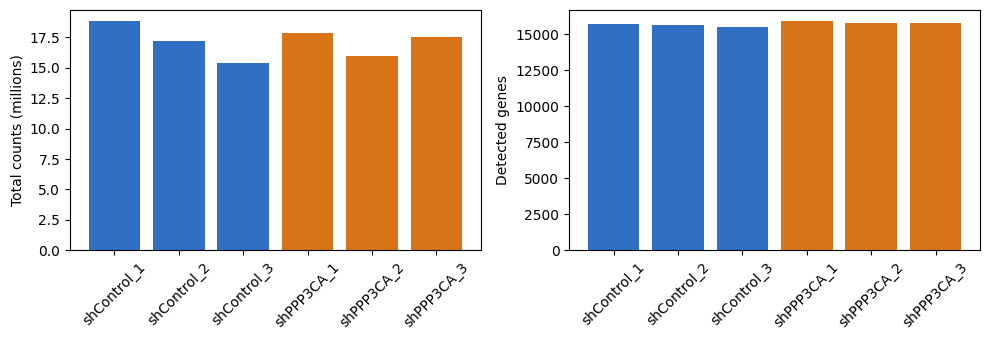

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].bar(qc.index, qc["total_counts"] / 1e6, color=colors)
axes[0].set_ylabel("Total counts (millions)")
axes[1].bar(qc.index, qc["detected_genes"], color=colors)
axes[1].set_ylabel("Detected genes")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## カウントの分布

遺伝子ごとのカウントは、0に近いものから数万を超えるものまで幅があります。そのままでは図にしにくいので、log₁₀(カウント + 1) に変えて、試料ごとの分布を重ねます。+1 は、カウントが0のときに対数が計算できなくなるのを避けるためです。

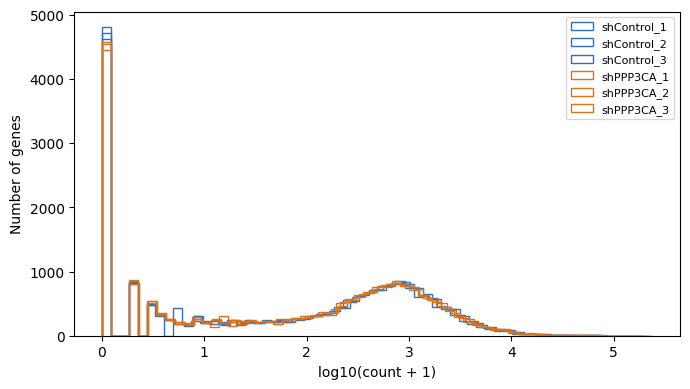

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
for s in counts.columns:
    ax.hist(np.log10(counts[s] + 1), bins=60, histtype="step", color=COLOR[samples.loc[s, "condition"]], label=s)
ax.set_xlabel("log10(count + 1)")
ax.set_ylabel("Number of genes")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

左端の高い山は、カウントが0か、ごく少ない遺伝子です。6つの線の形が似ていれば、試料のあいだで分布に大きな偏りはありません。

## カウントの少ない遺伝子を除く

カウントがごく少ない遺伝子は、偶然のばらつきが大きく、比べても確かなことが言えません。ここでは「カウントが10以上の試料が3つ以上ある遺伝子」だけを残します。3は、1つの条件の試料の数です。この基準は一例です。

In [7]:
MIN_COUNT = 10
MIN_SAMPLES = 3

keep = (counts >= MIN_COUNT).sum(axis=1) >= MIN_SAMPLES
counts_filtered = counts[keep]
print("除く前:", counts.shape[0], "遺伝子")
print("除いた後:", counts_filtered.shape[0], "遺伝子")

除く前: 20331 遺伝子
除いた後: 13131 遺伝子


## 図にするための変換（VST）

試料どうしを比べる図を作るために、カウントを VST（分散安定化変換）で変換します。VST は、試料ごとの合計の違いを調整し、対数に近い形に変える計算です。カウントの多い遺伝子ほどばらつきの幅も大きい、という偏りを小さくできます。計算には、03 でも使う PyDESeq2 を使います。

In [8]:
from pydeseq2.dds import DeseqDataSet

dds = DeseqDataSet(counts=counts_filtered.T, metadata=samples, design="~condition", quiet=True)
dds.vst()
vst = pd.DataFrame(dds.layers["vst_counts"].T, index=counts_filtered.index, columns=counts_filtered.columns)
vst.head()

,shControl_1,shControl_2,shControl_3,shPPP3CA_1,shPPP3CA_2,shPPP3CA_3
gene,,,,,,
A1BG,7.735477,7.794139,7.835262,7.781903,7.928231,7.830842
A2ML1,7.587200,7.485868,7.695062,7.512131,7.586202,7.607575
A4GALT,8.433984,8.510281,8.591134,8.335030,8.392168,8.341686
AAAS,10.410471,10.315968,10.286766,10.130914,10.113783,10.183026
AACS,10.802757,10.713627,10.707786,10.794272,10.836306,10.834936


## 試料どうしの相関

2つの試料で、全遺伝子の VST の値がどれくらいそろっているかを、相関係数で表します。1に近いほど似ています。

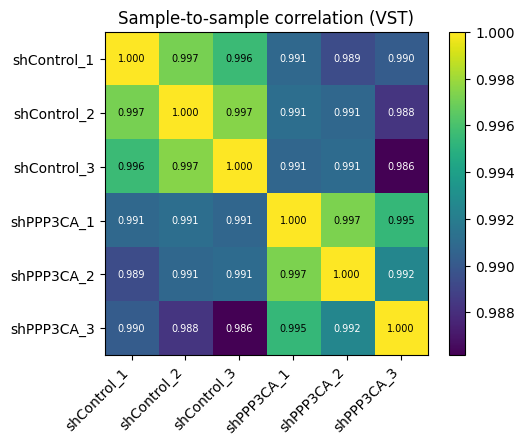

In [9]:
corr = vst.corr()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(corr, cmap="viridis")
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.3f}", ha="center", va="center", fontsize=7,
                color="black" if corr.iloc[i, j] > corr.values.mean() else "white")
fig.colorbar(im, ax=ax)
ax.set_title("Sample-to-sample correlation (VST)")
plt.tight_layout()
plt.show()

## PCA（主成分分析）

1つの試料は、約1万3千個の遺伝子の値を持っています。PCA は、試料どうしの違いをもっともよく表す軸を順に探し、2つの軸の平面に試料を並べる方法です。1つ目の軸を PC1、2つ目を PC2 と呼びます。近くに並ぶ試料ほど、遺伝子の値の全体が似ています。

ここでは、試料のあいだで値のばらつきが大きい上位500遺伝子を使います（R の DESeq2 の `plotPCA` と同じやり方です）。

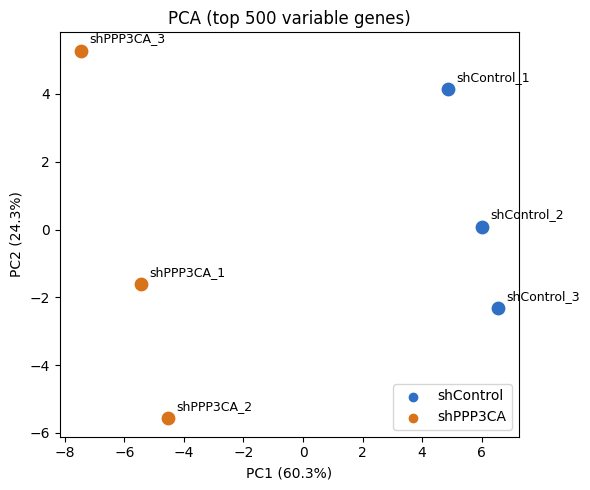

In [10]:
from sklearn.decomposition import PCA

N_TOP = 500
top = vst.var(axis=1).sort_values(ascending=False).index[:N_TOP]
X = vst.loc[top].T  # 行が試料、列が遺伝子
X = X - X.mean()

pca = PCA(n_components=2)
pcs = pca.fit_transform(X)
ratio = pca.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(6, 5))
for (s, (x, y)) in zip(X.index, pcs):
    ax.scatter(x, y, s=80, color=COLOR[samples.loc[s, "condition"]])
    ax.annotate(s, (x, y), textcoords="offset points", xytext=(6, 6), fontsize=9)
for cond, col in COLOR.items():
    ax.scatter([], [], color=col, label=cond)
ax.legend()
ax.set_xlabel(f"PC1 ({ratio[0]:.1f}%)")
ax.set_ylabel(f"PC2 ({ratio[1]:.1f}%)")
ax.set_title(f"PCA (top {N_TOP} variable genes)")
plt.tight_layout()
plt.show()

軸の名前の後ろの % は、その軸で試料どうしの違い全体のうちどれだけを表せているかです。


In [11]:
counts_filtered.to_csv("counts_filtered.csv")
vst.to_csv("vst.csv")

## 結果をダウンロードする

下のセルを実行すると、ここまでの結果をまとめた `results_02.zip` がパソコンにダウンロードされます。次の 03_DESeq2 の最初でアップロードしてください。

In [ ]:
import zipfile

OUT = "results_02.zip"
with zipfile.ZipFile(OUT, "w", zipfile.ZIP_DEFLATED) as z:
    for name in ['counts_filtered.csv', 'vst.csv']:
        z.write(name)
print(OUT, "に入れたファイル:", zipfile.ZipFile(OUT).namelist())

try:
    from google.colab import files
    files.download(OUT)
except ImportError:
    pass  # Colab 以外で実行したときは、手元のフォルダに保存される

次は **03_DESeq2** に進みます。

[https://colab.research.google.com/github/Yokohide0317/what_is_BI/blob/main/public/colab/03_DESeq2.ipynb](https://colab.research.google.com/github/Yokohide0317/what_is_BI/blob/main/public/colab/03_DESeq2.ipynb)